# 2016年 衆議院予算委員会 発言トピック・クラスタリング

クリーニング済みの5,928発言を、SudachiPy、TF-IDF、TruncatedSVD、KMeansで政策トピック別に分類します。乱数シードは固定され、同じ入力から同じ結果を再生成できます。

In [1]:
from pathlib import Path
import os
import sys
import warnings

ROOT = Path.cwd()
if not (ROOT / 'cleaned').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(ROOT))

from clustering_2016 import (
    FIXED_K, RANDOM_STATE, apply_manual_labels, cluster_details, compare_k,
    export_results, load_input, reduce_dimensions, vectorize,
)

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
INPUT = ROOT / 'cleaned/speeches_2016.jsonl'
OUTPUT_DIR = ROOT / 'analysis/clustering_2016'
print(f'Matplotlib font: {MAC_JAPANESE_FONT} ({mac_font_paths[0]})')
RANDOM_STATE

Matplotlib font: Hiragino Sans (/System/Library/Fonts/ヒラギノ角ゴシック W3.ttc)


42

## 1. 入力検証

件数、会議名、発言IDの一意性、本文の欠損・空文字を検証します。条件を満たさない場合はここで停止します。

In [2]:
df = load_input(INPUT)
validation = pd.Series({
    'rows': len(df),
    'unique_speech_ids': df['speechID'].nunique(),
    'meetings': df['nameOfMeeting'].nunique(),
    'missing_cleaned_text': int(df['speech_cleaned'].isna().sum()),
    'empty_cleaned_text': int(df['speech_cleaned'].str.strip().eq('').sum()),
    'review_flagged': int(df['review_flags'].map(bool).sum()),
})
display(validation.to_frame('value'))
display(df[['speechID', 'date', 'speaker', 'speakerPosition', 'speech_cleaned', 'review_flags']].head())

,value
rows,5928
unique_speech_ids,5928
meetings,1
missing_cleaned_text,0
empty_cleaned_text,0
review_flagged,503


,speechID,date,speaker,speakerPosition,speech_cleaned,review_flags
0,119205261X00620161214_000,2016-12-14,会議録情報,None,平成二十八年十二月十四日（水曜日） 午前十一時三十分開議 出席委員 委員長 浜田 靖一君 理...,[]
1,119205261X00520161012_000,2016-10-12,会議録情報,None,平成二十八年十月十二日（水曜日） 午前八時五十八分開議 出席委員 委員長 浜田 靖一君 理事...,[]
2,119205261X00520161012_006,2016-10-12,菅原一秀,None,おはようございます。自民党の菅原一秀です。 二十七分という時間でありますので、早速質問に入ら...,[]
3,119205261X00520161012_007,2016-10-12,松野博一,文部科学大臣,公立学校施設は、子供たちの学習、生活の場であるとともに、災害時には地域住民の避難所ともなる極...,[]
4,119205261X00520161012_008,2016-10-12,菅原一秀,None,三分の一の国の補助ですが、ぜひ、かさ上げも含めて、早急な対策をお願いしたいと思います。 次に...,[]


## 2. 日本語処理、TF-IDF、次元削減

SudachiPyで名詞・動詞・形容詞を正規形へ変換し、1〜2語gramのTF-IDFを作ります。100次元へ圧縮後、KMeans用に正規化します。

In [3]:
vectorizer, tfidf = vectorize(df)
svd, reduced = reduce_dimensions(tfidf)
zero_vectors = pd.DataFrame(columns=['speechID', 'speech_cleaned', 'reason'])
print(f'TF-IDF: {tfidf.shape[0]:,} rows × {tfidf.shape[1]:,} features')
print(f'SVD explained variance: {svd.explained_variance_ratio_.sum():.1%}')
print(f'Zero vectors: {len(zero_vectors)}')
display(pd.DataFrame({'component': range(1, 11), 'explained_variance': svd.explained_variance_ratio_[:10]}))

TF-IDF: 5,928 rows × 20,000 features
SVD explained variance: 16.3%
Zero vectors: 0


,component,explained_variance
0,1,0.014067
1,2,0.002706
2,3,0.004302
3,4,0.003783
4,5,0.003551
5,6,0.003368
6,7,0.003078
7,8,0.003065
8,9,0.002740
9,10,0.002633


## 3. 10クラスタで学習

クラスタ数を `k=10` に固定して学習します。固定した2,000件標本でsilhouette scoreを確認します。

Fixed k=10


,k,silhouette,inertia,smallest_cluster,largest_cluster
0,10,0.0627,"4,704.5",176,1884


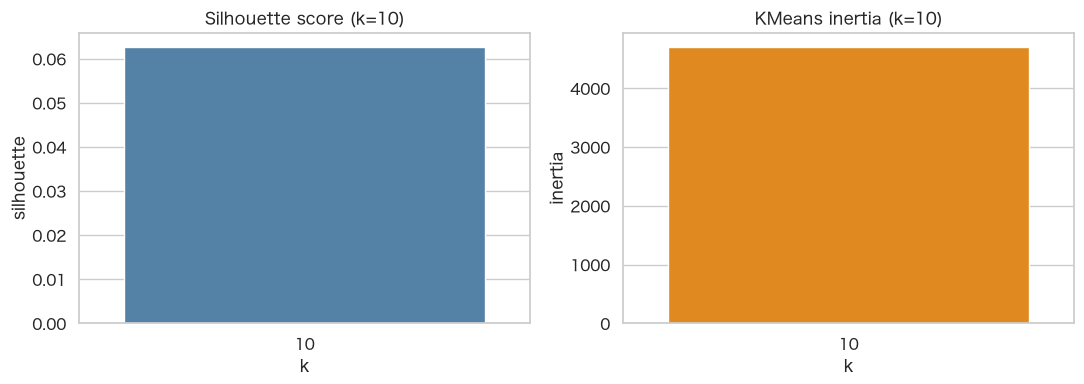

In [4]:
scores, models = compare_k(reduced, candidates=[FIXED_K])
best_k = FIXED_K
model = models[best_k]
print(f'Fixed k={best_k}')
display(scores.style.format({'silhouette': '{:.4f}', 'inertia': '{:,.1f}'}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=scores, x='k', y='silhouette', color='steelblue', ax=axes[0])
axes[0].set_title('Silhouette score (k=10)')
sns.barplot(data=scores, x='k', y='inertia', color='darkorange', ax=axes[1])
axes[1].set_title('KMeans inertia (k=10)')
plt.tight_layout();

## 4. クラスタの解釈

上位特徴語、重心に近い代表発言、主要話者、月別分布を確認します。暫定ラベルは上位3特徴語です。

,cluster,provisional_label,count,ratio,top_terms,representative_speech_ids
0,0,南スーダン・自衛隊・pko,176,3.0%,南スーダン | 自衛隊 | pko | 任務 | 部隊 | 国連 | 武器 | 警護 | 現地 | 活動 | 付与 | 派遣,119205261X00320161003_278 | 119205261X00220160930_197 | 119005261X00720160204_218 | 119005261X01720160229_215 | 119005261X01720160229_217
1,1,議論・憲法・自民党,697,11.8%,議論 | 憲法 | 自民党 | 国民 | 議員 | 番組 | 選挙 | 憲法改正 | 野党 | 民主党 | 与党 | 考え方,119005261X01820160301_044 | 119005261X00820160205_332 | 119005261X01220160215_190 | 119005261X00320160112_334 | 119005261X00820160205_348
2,2,甘利・ur・交渉,263,4.4%,甘利 | ur | 交渉 | 補償 | 秘書 | 事務所 | 甘利 事務所 | 補償 交渉 | 会見 | 斡旋 | 契約 | 果たす,119005261X01520160219_095 | 119005261X01320160216_006 | 119005261X02020160516_142 | 119005261X01620160222_191 | 119005261X01720160229_162
3,3,tpp・試算・影響,474,8.0%,tpp | 試算 | 影響 | 価格 | 輸入 | 関税 | 判断 | 日本 | 国内 | 調整金 | sbs | 裁判所,119005261X00420160113_113 | 119205261X00420161004_172 | 119005261X00720160204_322 | 119005261X00820160205_183 | 119005261X00820160205_185
4,4,発言短文・致す 発言短文・間違い 発言短文,191,3.2%,発言短文 | 致す 発言短文 | 間違い 発言短文 | 間違い | 事実 発言短文 | 正す | 致す | 宜しい 発言短文 | 撤回 | とめる | 事実 | 省庁,119205261X00520161012_038 | 119005261X00920160208_321 | 119205261X00320161003_246 | 119005261X00920160208_319 | 119005261X00920160208_188
5,5,経済・年金・マイナス,737,12.4%,経済 | 年金 | マイナス | 金利 | 上がる | 賃金 | 政権 | 下がる | 増える | 物価 | 消費税 | 安倍,119205261X00520161012_022 | 119005261X00920160208_009 | 119205261X00520161012_018 | 119005261X01620160222_076 | 119005261X01120160210_051
6,6,致す・対する・行う,1884,31.8%,致す | 対する | 行う | 先程 | 調査 | 伺う | 事実 | 資料 | 日本 | よる | 会計検査院 | 認識,119005261X00220160108_022 | 119005261X01120160210_330 | 119005261X02020160516_090 | 119205261X00420161004_060 | 119005261X02020160516_095
7,7,復興・災害・被災者,314,5.3%,復興 | 災害 | 被災者 | 被災地 | 避難 | 被害 | 住宅 | 復旧 | 福島 | 支援 | 被災 | 自治体,119205261X00520161012_040 | 119205261X00420161004_020 | 119205261X00220160930_033 | 119005261X01720160229_014 | 119205261X00420161004_207
8,8,支援・地域・地方,908,15.3%,支援 | 地域 | 地方 | よる | 日本 | 進める | 予算 | 年度 | 取り組む | 致す | 実現 | 社会,119005261X00220160108_077 | 119005261X01420160218_226 | 119205261X00220160930_052 | 119005261X00820160205_023 | 119005261X00220160108_071
9,9,税率・軽減・軽減 税率,284,4.8%,税率 | 軽減 | 軽減 税率 | 導入 | 社会保障 | 消費税 | 財源 | 制度 | 負担 | 税率 導入 | 給付 | 税額控除,119005261X01520160219_230 | 119005261X01520160219_197 | 119005261X01420160218_004 | 119005261X01520160219_053 | 119005261X01520160219_231


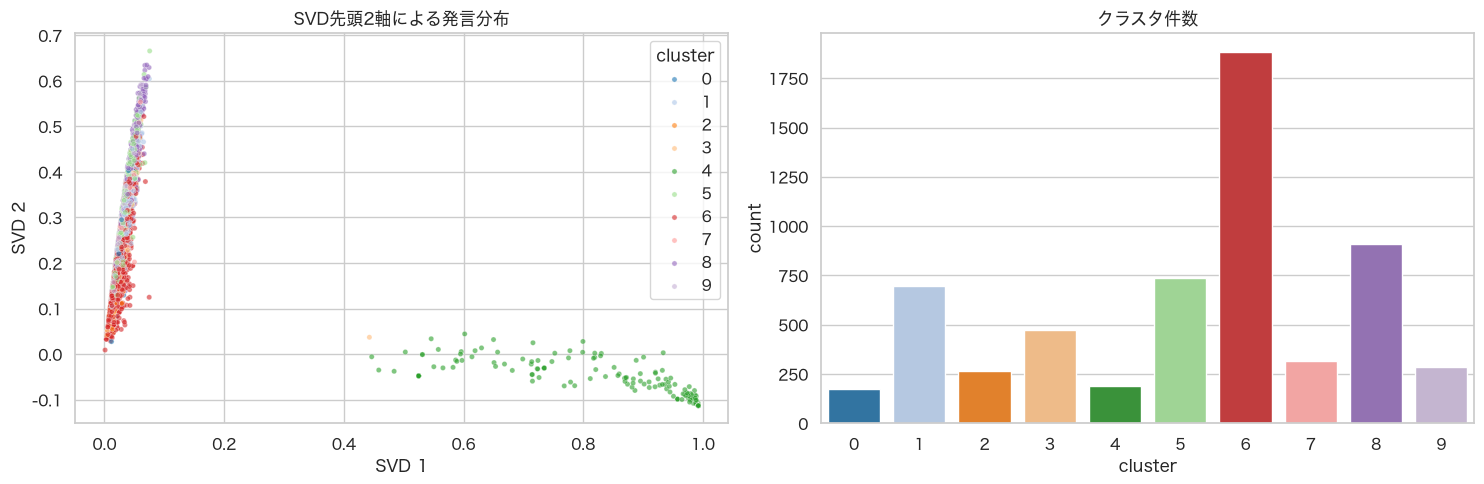

In [5]:
assignments, summary = cluster_details(df, tfidf, reduced, vectorizer, model)
display(summary.style.format({'ratio': '{:.1%}'}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x=reduced[:, 0], y=reduced[:, 1], hue=assignments['cluster'], palette='tab20', s=14, alpha=.6, legend='full', ax=axes[0])
axes[0].set(title='SVD先頭2軸による発言分布', xlabel='SVD 1', ylabel='SVD 2')
sns.barplot(data=summary, x='cluster', y='count', hue='cluster', palette='tab20', legend=False, ax=axes[1])
axes[1].set_title('クラスタ件数')
plt.tight_layout();

In [6]:
for cluster_id in summary['cluster']:
    row = summary.loc[summary['cluster'].eq(cluster_id)].iloc[0]
    members = assignments.loc[assignments['cluster'].eq(cluster_id)]
    representatives = members.nsmallest(5, 'centroid_distance')[['speechID', 'date', 'speaker', 'speech_cleaned', 'centroid_distance']]
    top_speakers = members['speaker'].value_counts().head(5).rename_axis('speaker').reset_index(name='count')
    print(f"\nCluster {cluster_id}: {row['provisional_label']} ({row['count']:,}件)")
    print(f"特徴語: {row['top_terms']}")
    display(top_speakers, representatives)


Cluster 0: 南スーダン・自衛隊・pko (176件)
特徴語: 南スーダン | 自衛隊 | pko | 任務 | 部隊 | 国連 | 武器 | 警護 | 現地 | 活動 | 付与 | 派遣


,speaker,count
0,笠井亮,42
1,稲田朋美,31
2,安倍晋三,20
3,中谷元,20
4,後藤祐一,18


,speechID,date,speaker,speech_cleaned,centroid_distance
837,119205261X00320161003_278,2016-10-03,笠井亮,双方が停戦命令を下した、停戦を表明したといっても、双方がやめますということで合意までできてい...,0.471077
1088,119205261X00220160930_197,2016-09-30,辻元清美,私たち国会議員は、例えば地元で式典があったり集会があったりします、この日も。でも、防衛大臣で...,0.477057
4720,119005261X00720160204_218,2016-02-04,安倍晋三,今の質問にお答えをする前に、先ほどの答弁をちょっと補足させていただきたいと思うんですが、南ス...,0.500256
1830,119005261X01720160229_215,2016-02-29,笠井亮,現在、南スーダンの国内避難民は百七十万人。うち二十万人が国連保護施設にいるとされて、北部にお...,0.511148
1832,119005261X01720160229_217,2016-02-29,笠井亮,昨年九月十九日に強行されて、三月末に施行される安保法制のＰＫＯ法の改定で、国連ＰＫＯ等での自...,0.520052



Cluster 1: 議論・憲法・自民党 (697件)
特徴語: 議論 | 憲法 | 自民党 | 国民 | 議員 | 番組 | 選挙 | 憲法改正 | 野党 | 民主党 | 与党 | 考え方


,speaker,count
0,安倍晋三,241
1,高市早苗,32
2,大串博志,30
3,奥野総一郎,26
4,山尾志桜里,25


...

,speaker,count
0,安倍晋三,165
1,塩崎恭久,79
2,麻生太郎,31
3,加藤勝信,24
4,高市早苗,24


,speechID,date,speaker,speech_cleaned,centroid_distance
5759,119005261X00220160108_077,2016-01-08,桝屋敬悟,厚労大臣の今のお答えは極めて大事な話だろうと思います。魅力を感じる職場、介護の職場が本当に志...,0.714566
2766,119005261X01420160218_226,2016-02-18,蓮井明博,ただいま御紹介いただきました一般社団法人四国地区信用金庫協会会長の蓮井明博と申します。 本日...,0.718896
960,119205261X00220160930_052,2016-09-30,とかしきなおみ,ありがとうございました。 ここからは、大阪の吹田市と摂津市で今現在取り組んでいるプロジェクト...,0.733300
4212,119005261X00820160205_023,2016-02-05,浮島智子,ありがとうございます。 努力をしていきたいという御答弁をいただきましたけれども、出生率一・八...,0.735473
5753,119005261X00220160108_071,2016-01-08,桝屋敬悟,ありがとうございます。 私どもの地元が一・四五。一・八に向けて頑張らなきゃいかぬな、こう思っ...,0.739736



Cluster 9: 税率・軽減・軽減 税率 (284件)
特徴語: 税率 | 軽減 | 軽減 税率 | 導入 | 社会保障 | 消費税 | 財源 | 制度 | 負担 | 税率 導入 | 給付 | 税額控除


,speaker,count
0,安倍晋三,56
1,麻生太郎,46
2,古川元久,11
3,山井和則,11
4,岡田克也,10


,speechID,date,speaker,speech_cleaned,centroid_distance
2501,119005261X01520160219_230,2016-02-19,宮本岳志,しかし、先ほど申し上げたように、痛税感の緩和というのは、つまり、軽減税率をしないよりは、した...,0.578790
2470,119005261X01520160219_197,2016-02-19,青柳陽一郎,何でわざわざ聞いたかといえば、私、昨年の予算委員会で同じことを質問しました。麻生大臣、全く逆...,0.591184
2571,119005261X01420160218_004,2016-02-18,小山展弘,民主党の小山展弘でございます。 早速質問に入らせていただきたいと思います。 まず、麻生財務大...,0.597281
2338,119005261X01520160219_053,2016-02-19,安倍晋三,先ほど西村議員はいろいろな例を挙げておられましたが、例えばカード決済については、靴をカード決...,0.598644
2502,119005261X01520160219_231,2016-02-19,安倍晋三,全くそんなことは考えておりません。 今回はまさに一〇％に引き上げるに当たって軽減税率を導入し...,0.602895


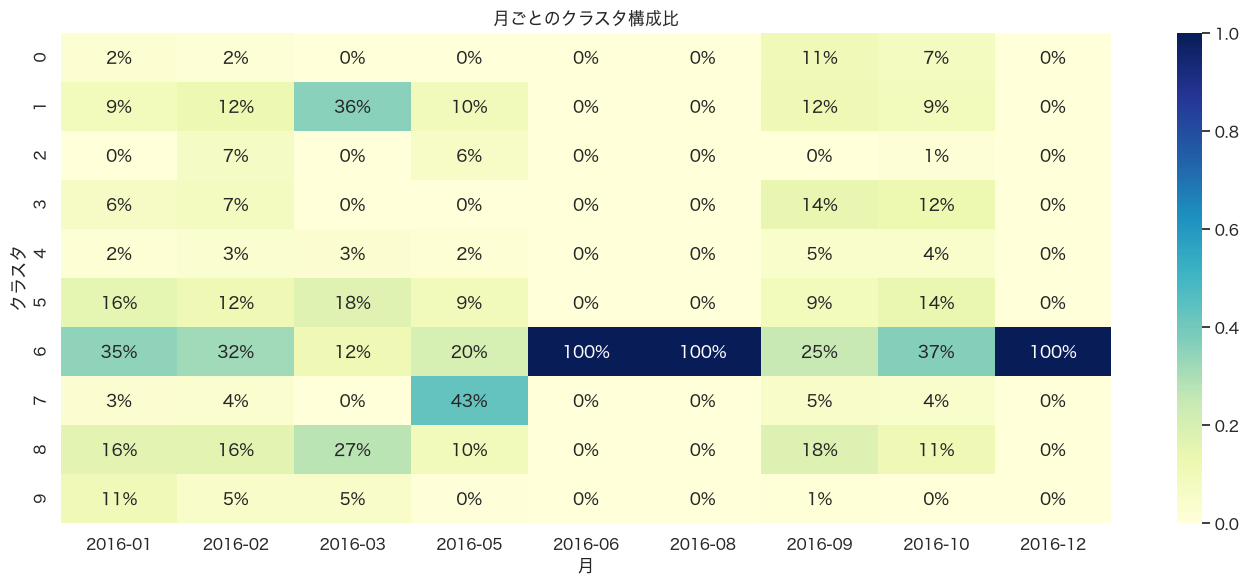

In [7]:
monthly = pd.crosstab(assignments['month'], assignments['cluster'], normalize='index')
plt.figure(figsize=(14, 6))
sns.heatmap(monthly.T, cmap='YlGnBu', annot=True, fmt='.0%')
plt.title('月ごとのクラスタ構成比')
plt.xlabel('月')
plt.ylabel('クラスタ')
plt.tight_layout();

## 5. 人手によるラベル調整

代表発言を確認し、必要なクラスタだけ辞書へ名称を追加してください。空のまま実行すると暫定ラベルを使用します。

In [8]:
MANUAL_CLUSTER_LABELS = {
    # 0: '社会保障・医療',
    # 1: '外交・安全保障',
}
assignments, summary = apply_manual_labels(assignments, summary, MANUAL_CLUSTER_LABELS)
display(summary[['cluster', 'cluster_label', 'count', 'ratio', 'top_terms']].style.format({'ratio': '{:.1%}'}))

,cluster,cluster_label,count,ratio,top_terms
0,0,南スーダン・自衛隊・pko,176,3.0%,南スーダン | 自衛隊 | pko | 任務 | 部隊 | 国連 | 武器 | 警護 | 現地 | 活動 | 付与 | 派遣
1,1,議論・憲法・自民党,697,11.8%,議論 | 憲法 | 自民党 | 国民 | 議員 | 番組 | 選挙 | 憲法改正 | 野党 | 民主党 | 与党 | 考え方
2,2,甘利・ur・交渉,263,4.4%,甘利 | ur | 交渉 | 補償 | 秘書 | 事務所 | 甘利 事務所 | 補償 交渉 | 会見 | 斡旋 | 契約 | 果たす
3,3,tpp・試算・影響,474,8.0%,tpp | 試算 | 影響 | 価格 | 輸入 | 関税 | 判断 | 日本 | 国内 | 調整金 | sbs | 裁判所
4,4,発言短文・致す 発言短文・間違い 発言短文,191,3.2%,発言短文 | 致す 発言短文 | 間違い 発言短文 | 間違い | 事実 発言短文 | 正す | 致す | 宜しい 発言短文 | 撤回 | とめる | 事実 | 省庁
5,5,経済・年金・マイナス,737,12.4%,経済 | 年金 | マイナス | 金利 | 上がる | 賃金 | 政権 | 下がる | 増える | 物価 | 消費税 | 安倍
6,6,致す・対する・行う,1884,31.8%,致す | 対する | 行う | 先程 | 調査 | 伺う | 事実 | 資料 | 日本 | よる | 会計検査院 | 認識
7,7,復興・災害・被災者,314,5.3%,復興 | 災害 | 被災者 | 被災地 | 避難 | 被害 | 住宅 | 復旧 | 福島 | 支援 | 被災 | 自治体
8,8,支援・地域・地方,908,15.3%,支援 | 地域 | 地方 | よる | 日本 | 進める | 予算 | 年度 | 取り組む | 致す | 実現 | 社会
9,9,税率・軽減・軽減 税率,284,4.8%,税率 | 軽減 | 軽減 税率 | 導入 | 社会保障 | 消費税 | 財源 | 制度 | 負担 | 税率 導入 | 給付 | 税額控除


## 6. CSV出力と最終検証

UTF-8 BOM付きで発言別結果とクラスタ要約を保存します。

In [9]:
assert len(assignments) == len(df)
assert assignments['cluster'].notna().all()
assert set(assignments['cluster']) == set(range(best_k))
assert summary['count'].sum() == len(df)
assert best_k == 10
assert len(scores) == 1

export_results(assignments, summary, OUTPUT_DIR)
clusters_path = OUTPUT_DIR / 'speech_clusters.csv'
summary_path = OUTPUT_DIR / 'cluster_summary.csv'
assert len(pd.read_csv(clusters_path)) == len(df)
assert len(pd.read_csv(summary_path)) == best_k
print(f'発言別結果: {clusters_path}')
print(f'クラスタ要約: {summary_path}')
print(f'検証完了: {len(assignments):,}件、{best_k}クラスタ')

発言別結果: /Users/tasskkiu2/kokkai/analysis/clustering_2016/speech_clusters.csv
クラスタ要約: /Users/tasskkiu2/kokkai/analysis/clustering_2016/cluster_summary.csv
検証完了: 5,928件、10クラスタ
